# 04. Rainfall IV diagnostics across M2–M7

This exploratory analysis repeats each MPS crime type (all, violent, property) and exposure (current year, previous year, prior 12 months) under M2–M7. Each of the 54 models uses the same complete MPS sale sample. The estimates include a first stage, reduced form, matched OLS, 2SLS, and a Wooldridge residual-inclusion test.

**Rainfall is not a validated instrument.** The pilot uses [Open-Meteo historical reanalysis](https://open-meteo.com/en/docs/historical-weather-api) assigned to LSOAs using mean sale coordinates. Only 21 distinct returned weather locations cover the sample. Finer [HadUK-Grid data](https://catalogue.ceda.ac.uk/uuid/789b3065d74a4c948ab05d33556c86d0/) would require separate access. Rainfall can directly affect prices through floods, damage, insurance, and sale timing; see this [Bank of England study](https://www.bankofengland.co.uk/working-paper/2020/high-water-no-marks-biased-lending-after-extreme-weather). Current-year rainfall includes months after some sales, which adds a timing problem.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from google.colab import drive
except ImportError:
    ROOT = Path.cwd()
else:
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/HE3027 Project')
sys.path.insert(0, str(ROOT))
OUT = ROOT/'data'/'04_crime_iv_outputs'
RESULT = OUT/'rainfall_m2_m7_iv_pilot.csv'
REESTIMATE = False
if REESTIMATE or not RESULT.exists():
    import rainfall_iv_sequence
    rainfall_iv_sequence.main()
results = pd.read_csv(RESULT)
models = [f'M{i}' for i in range(2,8)]
crimes = ['allcrime','violentcrime','propertycrime']
timings = ['annual','lagyear','prior12']
timing_labels = {'annual':'Current year','lagyear':'Previous year','prior12':'Prior 12 months'}
crime_labels = {'allcrime':'All crime','violentcrime':'Violent crime','propertycrime':'Property crime'}
assert len(results)==54 and results[['model','crime','exposure']].drop_duplicates().shape[0]==54
display(results.groupby('model',sort=False).agg(rows=('crime','size'),N_min=('N','min'),N_max=('N','max'),weather_cells=('weather_cell_clusters','min')))

,rows,N_min,N_max,weather_cells
model,,,,
M2,9,338347,338347,21
M3,9,338347,338347,21
M4,9,338347,338347,21
M5,9,338347,338347,21
M6,9,338347,338347,21
M7,9,338347,338347,21


## Model sequence and data

M2 has property controls; M3 adds transport, distance, and economic controls. M4 adds local-authority and year fixed effects; M5 uses MSOA and year; M6 uses MSOA and year-quarter; M7 uses LSOA and year-quarter. Job density is excluded to retain 2015. All models use complete observations for the full control set, so changes across models are not caused by changing N.

Rainfall is in 100 mm units. Standard errors are clustered by the 21 returned weather cells. These cells can themselves share shocks; inference is approximate with so few weather clusters. The exported LSOA-clustered first-stage F provides a comparison, though LSOA clustering alone ignores common rainfall within cells.

In [2]:
display(results.groupby('model',sort=False).first()[['controls','fixed_effects','N','lsoa_clusters','weather_cell_clusters']])
display(results[['model','crime','exposure','first_stage_beta_per_100mm','first_stage_se_weather_cell','first_stage_F_weather_cell','first_stage_F_lsoa','partial_R2','reduced_form_beta_per_100mm','reduced_form_p']].round(5))

,controls,fixed_effects,N,lsoa_clusters,weather_cell_clusters
model,,,,,
M2,detached_dum; semi_d_dum; terrace_dum; freehol...,NaN,338347,4647,21
M3,detached_dum; semi_d_dum; terrace_dum; freehol...,NaN,338347,4647,21
M4,detached_dum; semi_d_dum; terrace_dum; freehol...,oslaua; year,338347,4647,21
M5,detached_dum; semi_d_dum; terrace_dum; freehol...,msoa11; year,338347,4647,21
M6,detached_dum; semi_d_dum; terrace_dum; freehol...,msoa11; yearquarter,338347,4647,21
M7,detached_dum; semi_d_dum; terrace_dum; freehol...,lsoacode; yearquarter,338347,4647,21


,model,crime,exposure,first_stage_beta_per_100mm,first_stage_se_weather_cell,first_stage_F_weather_cell,first_stage_F_lsoa,partial_R2,reduced_form_beta_per_100mm,reduced_form_p
0,M2,allcrime,annual,0.01356,0.00559,5.88353,25.52380,0.00040,-0.03405,0.00041
1,M3,allcrime,annual,0.00405,0.00543,0.55663,1.72083,0.00004,0.00165,0.74706
2,M4,allcrime,annual,-0.12216,0.07982,2.34222,3.58689,0.00054,0.23451,0.02878
3,M5,allcrime,annual,0.01743,0.05192,0.11275,0.13513,0.00001,0.03801,0.03345
4,M6,allcrime,annual,0.01744,0.05190,0.11288,0.13516,0.00001,0.03532,0.04298
5,M7,allcrime,annual,0.08424,0.03391,6.17111,17.94564,0.00201,0.02069,0.33707
6,M2,violentcrime,annual,-0.02322,0.00519,20.01212,41.70348,0.00088,-0.03405,0.00041
7,M3,violentcrime,annual,-0.02947,0.00502,34.50532,51.31329,0.00142,0.00165,0.74706
8,M4,violentcrime,annual,-0.28938,0.10747,7.25021,17.98222,0.00231,0.23451,0.02878
9,M5,violentcrime,annual,-0.02311,0.04266,0.29347,0.25432,0.00001,0.03801,0.03345


## First-stage relevance

The heatmap shows the squared weather-cell-clustered t statistic on rainfall in each first stage. F ≥ 10 is only a rough relevance screen, not a claim of IV validity. Inspect the coefficient direction and partial R² as well. A first stage that fades after adding local and quarterly fixed effects has little usable variation for the preferred M7 specification.

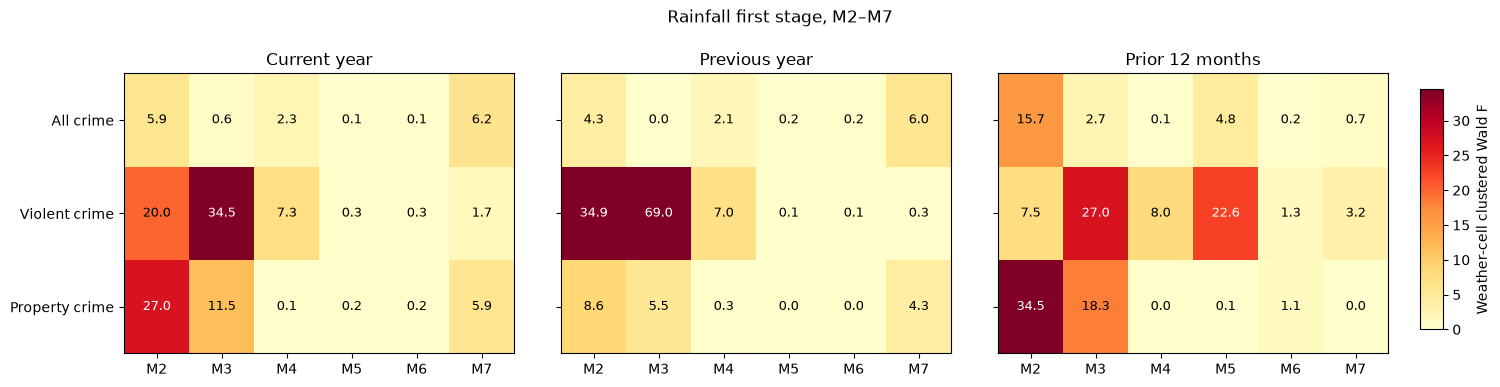

model                        M2       M3       M4       M5       M6       M7
crime         exposure                                                      
allcrime      annual    0.00040  0.00004  0.00054  0.00001  0.00001  0.00201
              lagyear   0.00034  0.00000  0.00052  0.00002  0.00002  0.00243
              prior12   0.00074  0.00011  0.00000  0.00003  0.00000  0.00001
propertycrime annual    0.00173  0.00100  0.00003  0.00002  0.00002  0.00196
              lagyear   0.00117  0.00049  0.00007  0.00000  0.00000  0.00172
              prior12   0.00177  0.00098  0.00000  0.00000  0.00001  0.00000
violentcrime  annual    0.00088  0.00142  0.00231  0.00001  0.00001  0.00030
              lagyear   0.00113  0.00292  0.00223  0.00000  0.00000  0.00004
              prior12   0.00047  0.00151  0.00018  0.00058  0.00001  0.00004

In [3]:
fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=True)
vmax=max(10,np.nanquantile(results.first_stage_F_weather_cell,.95))
for ax,t in zip(axes,timings):
    p=results.query('exposure==@t').pivot(index='crime',columns='model',values='first_stage_F_weather_cell').reindex(index=crimes,columns=models)
    im=ax.imshow(p.to_numpy(),cmap='YlOrRd',vmin=0,vmax=vmax,aspect='auto')
    for i in range(3):
        for j in range(6):
            v=p.iloc[i,j]
            ax.text(j,i,f'{v:.1f}',ha='center',va='center',fontsize=9,color='white' if v>vmax*.6 else 'black')
    ax.set_xticks(range(6),models); ax.set_yticks(range(3),[crime_labels[c] for c in crimes]); ax.set_title(timing_labels[t])
fig.suptitle('Rainfall first stage, M2–M7')
fig.subplots_adjust(top=.82,bottom=.12,left=.09,right=.88,wspace=.12)
fig.colorbar(im,cax=fig.add_axes([.90,.18,.014,.60]),label='Weather-cell clustered Wald F')
fig.savefig(OUT/'rainfall_first_stage_m2_m7.png',dpi=170,bbox_inches='tight'); plt.show()
display(results.pivot_table(index=['crime','exposure'],columns='model',values='partial_R2').round(5))

## Matched OLS, 2SLS, and exogeneity

The Wooldridge residual-inclusion test's null is that crime is exogenous **conditional on a valid instrument**. A p value below .05 rejects that null within the assumed IV model. Non-rejection does not prove exogeneity. A weak first stage makes the 2SLS and endogeneity results unreliable. Neither a test rejection nor a strong first stage proves rainfall's exclusion restriction.

The full CSV gives first-stage and reduced-form estimates, matched OLS and 2SLS coefficients with standard errors and approximate confidence intervals, and endogeneity statistics for every row.

,model,crime,exposure,N,first_stage_F_weather_cell,ols_beta,ols_se,ols_p,iv_beta,iv_se,iv_ci_low,iv_ci_high,iv_p,wooldridge_exogeneity_chi2,wooldridge_exogeneity_p
0,M2,allcrime,annual,338347,5.88353,0.12484,0.08061,0.13712,-2.51018,1.32361,-5.27118,0.25081,0.07244,19.47368,0.00001
1,M3,allcrime,annual,338347,0.55663,-0.03370,0.02792,0.24151,0.40780,1.60412,-2.93833,3.75392,0.80192,0.12946,0.71899
2,M4,allcrime,annual,338347,2.34222,-0.04272,0.02441,0.09541,-1.91969,1.11408,-4.24362,0.40423,0.10029,5.48909,0.01914
3,M5,allcrime,annual,338347,0.11275,-0.01034,0.00844,0.23479,2.18025,6.33764,-11.03983,15.40034,0.73442,5.15031,0.02324
4,M6,allcrime,annual,338347,0.11288,-0.01026,0.00864,0.24892,2.02548,5.86962,-10.21833,14.26928,0.73364,4.61005,0.03179
5,M7,allcrime,annual,338347,6.17111,0.00572,0.00459,0.22730,0.24564,0.27858,-0.33546,0.82674,0.38838,0.92385,0.33647
6,M2,violentcrime,annual,338347,20.01212,-0.08788,0.02997,0.00824,1.46620,0.49794,0.42751,2.50489,0.00801,21.04987,0.00000
7,M3,violentcrime,annual,338347,34.50532,-0.13473,0.01268,0.00000,-0.05604,0.16521,-0.40068,0.28859,0.73798,0.24432,0.62111
8,M4,violentcrime,annual,338347,7.25021,-0.13834,0.01446,0.00000,-0.81036,0.19160,-1.21003,-0.41069,0.00041,4.98990,0.02550
9,M5,violentcrime,annual,338347,0.29347,-0.05039,0.00521,0.00000,-1.64476,3.26894,-8.46365,5.17413,0.62036,4.56509,0.03263


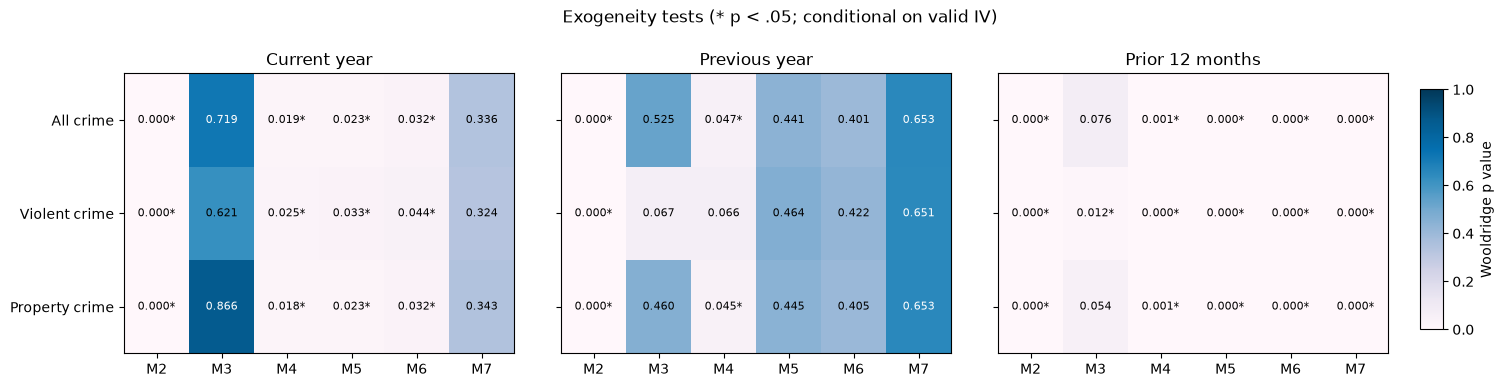

In [4]:
display(results[['model','crime','exposure','N','first_stage_F_weather_cell','ols_beta','ols_se','ols_p','iv_beta','iv_se','iv_ci_low','iv_ci_high','iv_p','wooldridge_exogeneity_chi2','wooldridge_exogeneity_p']].round(5))
fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=True)
for ax,t in zip(axes,timings):
    p=results.query('exposure==@t').pivot(index='crime',columns='model',values='wooldridge_exogeneity_p').reindex(index=crimes,columns=models)
    im=ax.imshow(p.to_numpy(),cmap='PuBu',vmin=0,vmax=1,aspect='auto')
    for i in range(3):
        for j in range(6):
            v=p.iloc[i,j]
            ax.text(j,i,f'{v:.3f}'+('*' if v<.05 else ''),ha='center',va='center',fontsize=8,color='white' if v>.65 else 'black')
    ax.set_xticks(range(6),models); ax.set_yticks(range(3),[crime_labels[c] for c in crimes]); ax.set_title(timing_labels[t])
fig.suptitle('Exogeneity tests (* p < .05; conditional on valid IV)')
fig.subplots_adjust(top=.82,bottom=.12,left=.09,right=.88,wspace=.12)
fig.colorbar(im,cax=fig.add_axes([.90,.18,.014,.60]),label='Wooldridge p value')
fig.savefig(OUT/'rainfall_endogeneity_m2_m7.png',dpi=170,bbox_inches='tight'); plt.show()

## Relevance screen and decision

The next table flags first stages with F ≥ 10. This only identifies where rainfall may predict crime after controls. It does not establish an exclusion restriction or justify a causal 2SLS estimate. The preferred main analysis remains M7. Finer rainfall could be tested later, but direct housing channels and shared spatial weather shocks would still need investigation.

In [5]:
screen=results[['model','crime','exposure','N','first_stage_beta_per_100mm','first_stage_F_weather_cell','partial_R2','wooldridge_exogeneity_p']].copy()
screen['F_at_least_10']=screen.first_stage_F_weather_cell.ge(10)
display(screen.round(5))
display(screen.groupby('model',sort=False).agg(F_at_least_10=('F_at_least_10','sum'),minimum_F=('first_stage_F_weather_cell','min'),maximum_F=('first_stage_F_weather_cell','max')).round(3))
print('Full results:',RESULT)
print('OLS and 2SLS:',OUT/'rainfall_regressions.csv')
print('Endogeneity tests:',OUT/'rainfall_endogeneity_tests.csv')

,model,crime,exposure,N,first_stage_beta_per_100mm,first_stage_F_weather_cell,partial_R2,wooldridge_exogeneity_p,F_at_least_10
0,M2,allcrime,annual,338347,0.01356,5.88353,0.00040,0.00001,False
1,M3,allcrime,annual,338347,0.00405,0.55663,0.00004,0.71899,False
2,M4,allcrime,annual,338347,-0.12216,2.34222,0.00054,0.01914,False
3,M5,allcrime,annual,338347,0.01743,0.11275,0.00001,0.02324,False
4,M6,allcrime,annual,338347,0.01744,0.11288,0.00001,0.03179,False
5,M7,allcrime,annual,338347,0.08424,6.17111,0.00201,0.33647,False
6,M2,violentcrime,annual,338347,-0.02322,20.01212,0.00088,0.00000,True
7,M3,violentcrime,annual,338347,-0.02947,34.50532,0.00142,0.62111,True
8,M4,violentcrime,annual,338347,-0.28938,7.25021,0.00231,0.02550,False
9,M5,violentcrime,annual,338347,-0.02311,0.29347,0.00001,0.03263,False


,F_at_least_10,minimum_F,maximum_F
model,,,
M2,5,4.273,34.855
M3,5,0.000,68.991
M4,0,0.001,7.955
M5,1,0.029,22.611
M6,0,0.029,1.295
M7,0,0.029,6.171


Full results: /home/rachmiel/he3027/data/04_crime_iv_outputs/rainfall_m2_m7_iv_pilot.csv
OLS and 2SLS: /home/rachmiel/he3027/data/04_crime_iv_outputs/rainfall_regressions.csv
Endogeneity tests: /home/rachmiel/he3027/data/04_crime_iv_outputs/rainfall_endogeneity_tests.csv
